## 1 Analyze the Dataset 

### 1.1 Import the Dataset

In [155]:
import pandas as pd
df = pd.read_excel("data/Pumpkin_Seeds_Dataset.xlsx")
display(df.head())

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Convex_Area,Equiv_Diameter,Eccentricity,Solidity,Extent,Roundness,Aspect_Ration,Compactness,Class
0,56276,888.242,326.1485,220.2388,56831,267.6805,0.7376,0.9902,0.7453,0.8963,1.4809,0.8207,Çerçevelik
1,76631,1068.146,417.1932,234.2289,77280,312.3614,0.8275,0.9916,0.7151,0.8440,1.7811,0.7487,Çerçevelik
2,71623,1082.987,435.8328,211.0457,72663,301.9822,0.8749,0.9857,0.7400,0.7674,2.0651,0.6929,Çerçevelik
3,66458,992.051,381.5638,222.5322,67118,290.8899,0.8123,0.9902,0.7396,0.8486,1.7146,0.7624,Çerçevelik
4,66107,998.146,383.8883,220.4545,67117,290.1207,0.8187,0.9850,0.6752,0.8338,1.7413,0.7557,Çerçevelik


### 1.2 Quality Check

#### Basic information

In [156]:
columns = df.columns
print("Dataset Shape: \n", df.shape)
print("---------------------------------------------------------\n")
print("Dataset Info: \n")
print(df.info())
print("---------------------------------------------------------\n")
print("Dataset Describe: \n", df.describe())

Dataset Shape: 
 (2500, 13)
---------------------------------------------------------

Dataset Info: 

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Area               2500 non-null   int64  
 1   Perimeter          2500 non-null   float64
 2   Major_Axis_Length  2500 non-null   float64
 3   Minor_Axis_Length  2500 non-null   float64
 4   Convex_Area        2500 non-null   int64  
 5   Equiv_Diameter     2500 non-null   float64
 6   Eccentricity       2500 non-null   float64
 7   Solidity           2500 non-null   float64
 8   Extent             2500 non-null   float64
 9   Roundness          2500 non-null   float64
 10  Aspect_Ration      2500 non-null   float64
 11  Compactness        2500 non-null   float64
 12  Class              2500 non-null   str    
dtypes: float64(10), int64(2), str(1)
memory usage: 254.0 KB
None
---------------

#### Missing values 

In [157]:
print("Missing Count: \n", df.isnull().sum())
print("---------------------------------------------------------\n")
print("Missing Value Ratio: \n", df.isnull().mean())
print("---------------------------------------------------------\n")
print("Missing Value Rows: ", df.isnull().any(axis = 1).sum())

Missing Count: 
 Area                 0
Perimeter            0
Major_Axis_Length    0
Minor_Axis_Length    0
Convex_Area          0
Equiv_Diameter       0
Eccentricity         0
Solidity             0
Extent               0
Roundness            0
Aspect_Ration        0
Compactness          0
Class                0
dtype: int64
---------------------------------------------------------

Missing Value Ratio: 
 Area                 0.0
Perimeter            0.0
Major_Axis_Length    0.0
Minor_Axis_Length    0.0
Convex_Area          0.0
Equiv_Diameter       0.0
Eccentricity         0.0
Solidity             0.0
Extent               0.0
Roundness            0.0
Aspect_Ration        0.0
Compactness          0.0
Class                0.0
dtype: float64
---------------------------------------------------------

Missing Value Rows:  0


#### Duplicate values

In [158]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


### 1.3 Exploratory Analysis

Countplot is used to compare the number of each category in the Class column to see if there is imbalance. The plot shows that the two classes are relatively balanced.

Class
Çerçevelik       1300
Ürgüp Sivrisi    1200
Name: count, dtype: int64


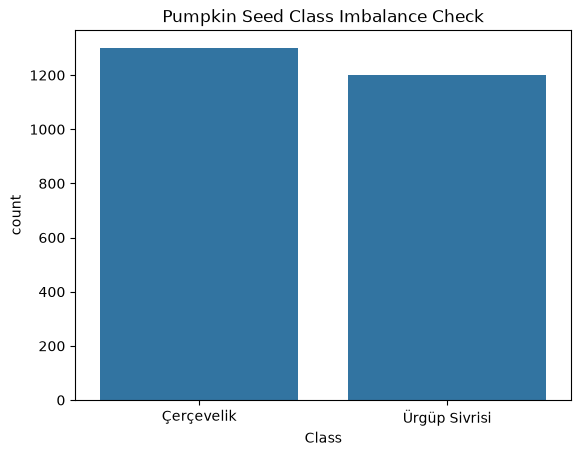

In [159]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df['Class'].value_counts())

sns.countplot(data=df,x='Class')
plt.title("Pumpkin Seed Class Imbalance Check")
plt.show()

Boxplot helps visualize how feature values differ between the two Classes. The 12 plots shows that the feature Major_Axis_Length, Minor_Axis_Length, Eccentricity, Roundness, Aspect_Ration and Compactness has noticeable differences between the two classes. Furthermore, there are several outliers indicated in the plots.

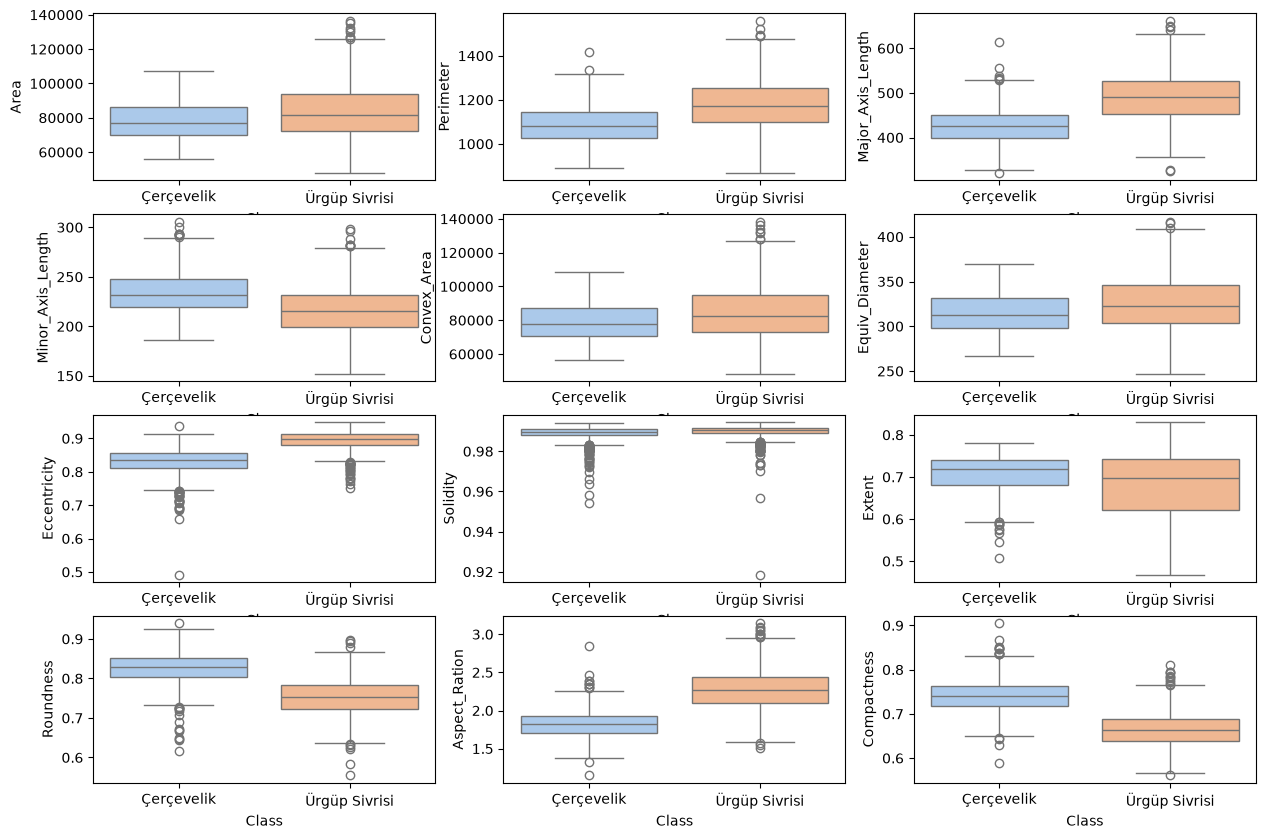

In [160]:
features = ['Area',	'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Convex_Area', 'Equiv_Diameter','Eccentricity', 'Solidity', 	'Extent',	'Roundness',	'Aspect_Ration',	'Compactness']
fig = plt.figure(figsize=(15,10))

for i in range(len(features)):
  sub=fig.add_subplot(4,3, i+1)
  sns.boxplot(x='Class', y=features[i], data=df, palette='pastel', hue='Class')

## 2 Train a Binary Classifier 

### 2.1 Split Dataset into Training and Testing Set

The dataset is split into 80% of training data and 20% of test data.

In [161]:
from sklearn.model_selection import train_test_split

X = df.drop(['Class'], axis=1)
y = df["Class"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=97)

print(f"Training data shape: X={X_train.shape}, Y={y_train.shape}")
print(f"Test data shape: X={X_test.shape}, Y={y_test.shape}")

Training data shape: X=(2000, 12), Y=(2000,)
Test data shape: X=(500, 12), Y=(500,)


### 2.2 Baseline Model: Logistic Regression

In [162]:
from sklearn.linear_model import LogisticRegression

baseline_model = LogisticRegression(solver='liblinear')
baseline_model.fit(X_train, y_train) 
y_pred = baseline_model.predict(X_test) 

print("Predictions: ", y_pred[:10])
print("True values: ", y_test.iloc[:10].values)

Predictions:  ['Çerçevelik' 'Ürgüp Sivrisi' 'Çerçevelik' 'Ürgüp Sivrisi' 'Çerçevelik'
 'Çerçevelik' 'Çerçevelik' 'Ürgüp Sivrisi' 'Çerçevelik' 'Çerçevelik']
True values:  <StringArray>
[   'Çerçevelik', 'Ürgüp Sivrisi',    'Çerçevelik', 'Ürgüp Sivrisi',
    'Çerçevelik',    'Çerçevelik',    'Çerçevelik', 'Ürgüp Sivrisi',
    'Çerçevelik',    'Çerçevelik']
Length: 10, dtype: str


### 2.3 Performance

The performance of the baseline model is evaluated by four metrics:

$$Accuracy = \frac{\text{TP + TN}}{\text{All}}$$

$$Precision = \frac{\text{TP}}{\text{TP + FP}}$$

$$Recall = \frac{\text{TP}}{\text{TP + FN}}$$

$$F1 = 2 * \frac{\text{Precision * Recall}}{\text{Precision + Recall}}$$

In [163]:
from sklearn import metrics
from sklearn.metrics import classification_report
print(metrics.accuracy_score(y_test, y_pred))
print(classification_report(y_test,y_pred))

0.86
               precision    recall  f1-score   support

   Çerçevelik       0.82      0.93      0.87       257
Ürgüp Sivrisi       0.91      0.79      0.85       243

     accuracy                           0.86       500
    macro avg       0.87      0.86      0.86       500
 weighted avg       0.87      0.86      0.86       500



Based on the result above, the accuracy of the baseline model is 0.86, which means there are 86% correct predictions in the test data. The precision of Cercevelik is 0.82, which means there are 82% correct prediction in the pumpkin seed predicted by the baseline model actually belong to the Class Cercevelik. The recall of Cercevelik is 0.93, that means the baseline model successfully recognized 93% of Cercevelik. F1 Score of the Cervevelik is 0.87, which balances precision and recall.

Since logistic regression use linear relationship and there are overlapping features distribution in the two classes of the pumpkin seeds, so it might not be able to capture the nonlinear relationship between features and the class.

### 2.4 Possible Improvement

There are two possible improvments, firsts is the cross-validation, it allows the model to utilize the dataset and make the evaluation performance to be more stable. The second is to compare with other models to evaluate if they can capture the relationship between the features and the class.

## 3 Improve the model’s performance

### 3.1 Feature Selection

Based on the boxplots in section 1.3, the feature with clear differentiation should keep, meanwhile, according to the physical meanings of each feature, the 6 features describing the size and shape: Major_Axis_Length, Minor_Axis_Length, Eccentricity, Roundness, Aspect_Ration and Compactness should be selected, and they may be helpful to distinguish between the two classes.

In [164]:
selected_features = ['Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Roundness', 'Aspect_Ration','Compactness']
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]
print("The features after feature selected is: ", X_train_selected.shape[1], " = ",X_test_selected.shape[1])

The features after feature selected is:  6  =  6


In [165]:
baseline_model_selected = LogisticRegression(solver='liblinear')
baseline_model_selected.fit(X_train_selected, y_train) 
y_pred_selected = baseline_model_selected.predict(X_test_selected) 

print("Predictions: ", y_pred_selected[:10])
print("True values: ", y_test.iloc[:10].values)

Predictions:  ['Çerçevelik' 'Ürgüp Sivrisi' 'Ürgüp Sivrisi' 'Ürgüp Sivrisi' 'Çerçevelik'
 'Çerçevelik' 'Çerçevelik' 'Ürgüp Sivrisi' 'Çerçevelik' 'Çerçevelik']
True values:  <StringArray>
[   'Çerçevelik', 'Ürgüp Sivrisi',    'Çerçevelik', 'Ürgüp Sivrisi',
    'Çerçevelik',    'Çerçevelik',    'Çerçevelik', 'Ürgüp Sivrisi',
    'Çerçevelik',    'Çerçevelik']
Length: 10, dtype: str


In [166]:
print("The performance before the feature selected: ")
print(metrics.accuracy_score(y_test, y_pred))
print(classification_report(y_test,y_pred))
print("The performance after the feature selected: ")
print(metrics.accuracy_score(y_test, y_pred_selected))
print(classification_report(y_test,y_pred_selected))

The performance before the feature selected: 
0.86
               precision    recall  f1-score   support

   Çerçevelik       0.82      0.93      0.87       257
Ürgüp Sivrisi       0.91      0.79      0.85       243

     accuracy                           0.86       500
    macro avg       0.87      0.86      0.86       500
 weighted avg       0.87      0.86      0.86       500

The performance after the feature selected: 
0.852
               precision    recall  f1-score   support

   Çerçevelik       0.83      0.90      0.86       257
Ürgüp Sivrisi       0.89      0.80      0.84       243

     accuracy                           0.85       500
    macro avg       0.86      0.85      0.85       500
 weighted avg       0.85      0.85      0.85       500



By comparing the performance metrics before and after the feature selected, the overall performance is decreased, which the accuracy decreased slightly from 0.86 to 0.852. However, the precision of Cercevelik and recall of Urgup Sivrisi is increased. Therefore, the Feature Selection in this dataset produced a trade-off between different metrics.

### 3.2 Hyperparameter Tuning

In [167]:
from sklearn.model_selection import GridSearchCV
# the document API suggest C chosen in a logarithmic scale between 1e-4 and 1e4
coeficient = {'C': [1e-4,1e-3,1e-2,1e-1,1e0,1e1,1e2,1e3,1e4]}

grid_search = GridSearchCV(
    estimator=LogisticRegression(solver='liblinear'),
    param_grid=coeficient,
    cv=5,
    scoring='accuracy'
)
grid_result = grid_search.fit(X_train_selected, y_train)
print(f"Best: {grid_result.best_score_} using {grid_result.best_params_}")

Best: 0.8734999999999999 using {'C': 0.1}


In [168]:
baseline_model_tuned = grid_result.best_estimator_
y_pred_tuned = baseline_model_tuned.predict(X_test_selected) 

print("Predictions: ", y_pred_tuned[:10])
print("True values: ", y_test.iloc[:10].values)


Predictions:  ['Çerçevelik' 'Ürgüp Sivrisi' 'Ürgüp Sivrisi' 'Ürgüp Sivrisi' 'Çerçevelik'
 'Çerçevelik' 'Çerçevelik' 'Ürgüp Sivrisi' 'Çerçevelik' 'Çerçevelik']
True values:  <StringArray>
[   'Çerçevelik', 'Ürgüp Sivrisi',    'Çerçevelik', 'Ürgüp Sivrisi',
    'Çerçevelik',    'Çerçevelik',    'Çerçevelik', 'Ürgüp Sivrisi',
    'Çerçevelik',    'Çerçevelik']
Length: 10, dtype: str


In [169]:
print("The performance before the feature selected: ")
print(metrics.accuracy_score(y_test, y_pred))
print(classification_report(y_test,y_pred))
print("The performance after the feature selected: ")
print(metrics.accuracy_score(y_test, y_pred_selected))
print(classification_report(y_test,y_pred_selected))
print("The performance after the hyperparameter tuning: ")
print(metrics.accuracy_score(y_test, y_pred_tuned))
print(classification_report(y_test,y_pred_tuned))

The performance before the feature selected: 
0.86
               precision    recall  f1-score   support

   Çerçevelik       0.82      0.93      0.87       257
Ürgüp Sivrisi       0.91      0.79      0.85       243

     accuracy                           0.86       500
    macro avg       0.87      0.86      0.86       500
 weighted avg       0.87      0.86      0.86       500

The performance after the feature selected: 
0.852
               precision    recall  f1-score   support

   Çerçevelik       0.83      0.90      0.86       257
Ürgüp Sivrisi       0.89      0.80      0.84       243

     accuracy                           0.85       500
    macro avg       0.86      0.85      0.85       500
 weighted avg       0.85      0.85      0.85       500

The performance after the hyperparameter tuning: 
0.842
               precision    recall  f1-score   support

   Çerçevelik       0.82      0.89      0.85       257
Ürgüp Sivrisi       0.88      0.79      0.83       243

     accu

After the hyperparameter tuning, during the cross-validation, the best cv accuracy is 0.8735, however, the hyperparameter tuning does not improved the performance of the model on the test data.

### 3.3 Alternative Model

In [170]:
from sklearn.svm import SVC

alternative_model= SVC()
alternative_model.fit(X_train_selected, y_train) 
y_pred_alternative = alternative_model.predict(X_test_selected) 

print("Predictions: ", y_pred_alternative[:10])
print("True values: ", y_test.iloc[:10].values)

Predictions:  ['Çerçevelik' 'Ürgüp Sivrisi' 'Çerçevelik' 'Ürgüp Sivrisi' 'Çerçevelik'
 'Çerçevelik' 'Çerçevelik' 'Ürgüp Sivrisi' 'Çerçevelik' 'Çerçevelik']
True values:  <StringArray>
[   'Çerçevelik', 'Ürgüp Sivrisi',    'Çerçevelik', 'Ürgüp Sivrisi',
    'Çerçevelik',    'Çerçevelik',    'Çerçevelik', 'Ürgüp Sivrisi',
    'Çerçevelik',    'Çerçevelik']
Length: 10, dtype: str


In [171]:
print("The performance before the feature selected: ")
print(metrics.accuracy_score(y_test, y_pred))
print(classification_report(y_test,y_pred))
print("The performance after the feature selected: ")
print(metrics.accuracy_score(y_test, y_pred_selected))
print(classification_report(y_test,y_pred_selected))
print("The performance after the hyperparameter tuning: ")
print(metrics.accuracy_score(y_test, y_pred_tuned))
print(classification_report(y_test,y_pred_tuned))
print("The performance of the SVC model: ")
print(metrics.accuracy_score(y_test, y_pred_alternative))
print(classification_report(y_test,y_pred_alternative))

The performance before the feature selected: 
0.86
               precision    recall  f1-score   support

   Çerçevelik       0.82      0.93      0.87       257
Ürgüp Sivrisi       0.91      0.79      0.85       243

     accuracy                           0.86       500
    macro avg       0.87      0.86      0.86       500
 weighted avg       0.87      0.86      0.86       500

The performance after the feature selected: 
0.852
               precision    recall  f1-score   support

   Çerçevelik       0.83      0.90      0.86       257
Ürgüp Sivrisi       0.89      0.80      0.84       243

     accuracy                           0.85       500
    macro avg       0.86      0.85      0.85       500
 weighted avg       0.85      0.85      0.85       500

The performance after the hyperparameter tuning: 
0.842
               precision    recall  f1-score   support

   Çerçevelik       0.82      0.89      0.85       257
Ürgüp Sivrisi       0.88      0.79      0.83       243

     accu

The alternative SVC model has the accuracy 0.852, the performance of SVC is better than the baseline model with hyperparameter tuning but worse than the original baseline logistic regression model. This might be because of the characteristics of SVC, since the two pumpkin seeds look not too much different and have overlapping feature distributions, so that there is not a very clear division line between two class.

## 4 GitHub Repository Link

https://github.com/JiaxuanTong/Pumpkin-Seeds-Binary-Classification